In [1]:
import os
import sys
import pandas as pd
import numpy as np
import muon as mu
import scanpy as sc
import anndata as ad
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

import pickle

from scipy.cluster.hierarchy import fcluster
from scipy.cluster.hierarchy import dendrogram, linkage
from matplotlib.patches import Rectangle
import matplotlib.patches as mpatches

import re
import seaborn as sns

In [2]:
work_dir = '/lustre/scratch125/casm/team215mg/od5/organoid_immune/multiome/scenicplus/all_cells/'

In [3]:
output_dir = work_dir + 'scenicplus_full/eRegulon_AUC_dotplot/'
os.makedirs(output_dir, exist_ok=True)

In [4]:
grouping_var = 'anno_v1_nuc_gex'

In [5]:
## Read AUC object
gene_auc = pd.read_csv(work_dir + 'scenicplus_full/eRegulon_AUC_genes.csv', index_col=0)

In [6]:
gene_auc

,AHCTF1_-_+_(83g),AHDC1_+_+_(78g),AHDC1_-_+_(30g),AHR_+_+_(89g),AHR_-_+_(93g),ARID3A_+_+_(214g),ARID3A_-_+_(25g),ARID5B_+_+_(62g),ARID5B_-_+_(11g),ARNTL2_+_+_(23g),...,ZNF704_+_+_(47g),ZNF704_-_+_(63g),ZNF76_+_+_(12g),ZNF770_-_+_(24g),ZNF771_+_+_(15g),ZNF783_+_+_(20g),ZNF808_+_+_(14g),ZNF83_+_+_(14g),ZNF93_-_+_(90g),ZSCAN18_+_+_(55g)
Cell,,,,,,,,,,,,,,,,,,,,,
run_002_0-SEACell-0,0.0,0.000000,0.0,0.023756,0.001229,0.0,0.000000,0.002765,0.0,0.016770,...,0.003343,0.005669,0.0,0.0,0.0,0.0,0.0,0.0,0.006825,0.0
run_002_0-SEACell-1,0.0,0.000000,0.0,0.022632,0.000000,0.0,0.000000,0.000922,0.0,0.000000,...,0.006991,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0
run_002_0-SEACell-2,0.0,0.000000,0.0,0.008026,0.000000,0.0,0.000000,0.009677,0.0,0.000000,...,0.014286,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.003810,0.0
run_002_0-SEACell-3,0.0,0.000000,0.0,0.029695,0.000000,0.0,0.000000,0.002074,0.0,0.000000,...,0.009422,0.013379,0.0,0.0,0.0,0.0,0.0,0.0,0.006508,0.0
run_002_0-SEACell-4,0.0,0.000000,0.0,0.013804,0.000000,0.0,0.000000,0.008986,0.0,0.006211,...,0.000000,0.002721,0.0,0.0,0.0,0.0,0.0,0.0,0.006349,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
run_010_3-SEACell-5,0.0,0.000000,0.0,0.016372,0.000000,0.0,0.000000,0.002074,0.0,0.000000,...,0.000000,0.007483,0.0,0.0,0.0,0.0,0.0,0.0,0.014603,0.0
run_010_3-SEACell-6,0.0,0.010073,0.0,0.011075,0.000000,0.0,0.000000,0.000000,0.0,0.014286,...,0.000000,0.005669,0.0,0.0,0.0,0.0,0.0,0.0,0.021111,0.0
run_010_3-SEACell-7,0.0,0.000000,0.0,0.000161,0.000000,0.0,0.000000,0.000000,0.0,0.000000,...,0.000000,0.009751,0.0,0.0,0.0,0.0,0.0,0.0,0.010159,0.0


In [7]:
## Read mdata object
mdata = mu.read_h5mu('/lustre/scratch125/casm/team215mg/od5/organoid_immune/multiome/seacells_gex/all_cells/seacells_annot_min10cells.h5mu')

/lustre/scratch125/casm/team215mg/od5/miniconda3/envs/multiome/lib/python3.9/site-packages/mudata/_core/mudata.py:578: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  data_mod.loc[:, colname] = col
/lustre/scratch125/casm/team215mg/od5/miniconda3/envs/multiome/lib/python3.9/site-packages/mudata/_core/mudata.py:578: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  data_mod.loc[:, colname] = col


In [8]:
mdata['rna'].X.sum(axis=1)

matrix([[10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [10000.],
        [1

In [9]:
## Log1p normalise
sc.pp.log1p(mdata['rna'])

In [10]:
## Identify TFs
tfs = pd.Series(gene_auc.columns).str.split('_', expand=True)[0].unique()

In [11]:
## Summarise AUC per grouping variable (e.g., cell type)
mean_auc = []
## Get mean expression - expects scaled and log1p object
mean_tf_exp = []
for ct in mdata.obs[grouping_var].unique():
    ## Identify cells
    cells = mdata.obs_names[mdata.obs[grouping_var]==ct]
    ## Mean AUC
    mean_auc.append(np.ravel(gene_auc.loc[cells, :].mean(axis=0)))
    ## Mean AUC
    mean_tf_exp.append(np.ravel(mdata['rna'][cells, tfs].X.mean(axis=0)))

auc_pseudo = pd.DataFrame(np.vstack(mean_auc), index=mdata.obs[grouping_var].unique().tolist(), columns=gene_auc.columns)
tf_exp_pseudo = pd.DataFrame(np.vstack(mean_tf_exp), index=mdata.obs[grouping_var].unique().tolist(), columns=tfs.tolist())

In [12]:
auc_pseudo.max(axis=0).describe()

count    393.000000
mean       0.005105
std        0.007799
min        0.000000
25%        0.000450
50%        0.002453
75%        0.006797
max        0.069870
dtype: float64

In [13]:
## Keeping TFs with AUC > 0
auc_pseudo = auc_pseudo.loc[:, auc_pseudo.max(axis=0) > 0]

In [14]:
auc_pseudo

,AHDC1_+_+_(78g),AHDC1_-_+_(30g),AHR_+_+_(89g),AHR_-_+_(93g),ARID3A_+_+_(214g),ARID3A_-_+_(25g),ARID5B_+_+_(62g),ARID5B_-_+_(11g),ARNTL2_+_+_(23g),ASCL2_+_+_(224g),...,ZNF407_+_+_(30g),ZNF518A_+_+_(49g),ZNF518A_-_+_(216g),ZNF529_-_+_(33g),ZNF566_+_+_(17g),ZNF704_+_+_(47g),ZNF704_-_+_(63g),ZNF770_-_+_(24g),ZNF83_+_+_(14g),ZNF93_-_+_(90g)
Cycling,0.000509,0.000389,0.006177,0.000123,0.001148,0.003544,0.005042,0.000000,0.003292,0.003443,...,0.003233,0.001408,0.003754,0.006725,0.000957,0.003016,0.010171,0.000000,0.000064,0.005607
Differentiated_noncycling,0.001534,0.000058,0.006417,0.000068,0.001255,0.003352,0.001963,0.000394,0.003079,0.002109,...,0.002040,0.000580,0.001887,0.005111,0.000000,0.002050,0.011635,0.000051,0.000155,0.007505
Stemlike_noncycling_TNFRSF19,0.000191,0.000212,0.004477,0.002410,0.001297,0.000863,0.010143,0.000000,0.000649,0.006797,...,0.003037,0.004742,0.001233,0.002780,0.000093,0.000838,0.007155,0.000317,0.000000,0.003111
Stemlike_noncycling,0.000632,0.000276,0.005999,0.000369,0.000854,0.004062,0.007680,0.000000,0.001620,0.003891,...,0.003891,0.001800,0.001560,0.007781,0.000606,0.002044,0.009557,0.000097,0.000000,0.004036
KRThigh_noncycling,0.001243,0.000061,0.006113,0.000369,0.000667,0.003159,0.003018,0.000000,0.007391,0.004681,...,0.000912,0.000496,0.004810,0.011769,0.001261,0.000912,0.012112,0.000000,0.000248,0.009776
MECOMhigh_noncycling,0.000085,0.000000,0.007679,0.000442,0.000907,0.004808,0.003776,0.000000,0.003412,0.002736,...,0.003168,0.000824,0.003000,0.006574,0.001154,0.001747,0.008977,0.000000,0.000000,0.006277
Cycling_GATA6,0.000837,0.000442,0.006076,0.000257,0.001228,0.000519,0.003479,0.000000,0.002355,0.004795,...,0.002455,0.001527,0.003681,0.009410,0.000115,0.002462,0.012562,0.000000,0.000000,0.006160
Neuroendocrine,0.000000,0.000000,0.004601,0.000000,0.001096,0.000000,0.017992,0.000000,0.000000,0.004741,...,0.008254,0.001458,0.001912,0.001623,0.002031,0.001418,0.008541,0.000000,0.000000,0.002526


In [15]:
tf_exp_pseudo

,AHCTF1,AHDC1,AHR,ARID3A,ARID5B,ARNTL2,ASCL2,ATF1,ATF3,ATF4,...,ZNF652,ZNF704,ZNF76,ZNF770,ZNF771,ZNF783,ZNF808,ZNF83,ZNF93,ZSCAN18
Cycling,1.119310,0.205772,1.499727,0.265718,1.254585,0.599055,0.393443,0.753873,0.666733,1.071776,...,0.837266,0.631871,0.218449,0.438859,0.125655,0.240703,0.184872,0.416475,0.196455,0.065831
Differentiated_noncycling,0.974046,0.258844,1.562487,0.359757,1.156526,0.476944,0.233147,0.727704,0.798922,1.069608,...,0.836993,0.511587,0.193172,0.407259,0.098557,0.232378,0.192330,0.478477,0.142428,0.071887
Stemlike_noncycling_TNFRSF19,1.037344,0.147361,1.346935,0.286573,1.263787,0.555109,0.572132,0.833268,0.779096,1.001264,...,0.838369,0.872145,0.295465,0.389312,0.108179,0.290387,0.156730,0.522585,0.258316,0.138635
Stemlike_noncycling,1.019400,0.207336,1.492156,0.269577,1.376019,0.486058,0.442003,0.733613,0.739845,0.956528,...,0.859751,0.683251,0.258405,0.417560,0.128517,0.282870,0.194613,0.423606,0.207798,0.093291
KRThigh_noncycling,1.065933,0.245000,1.600772,0.222042,1.159796,0.588018,0.345617,0.663306,0.499486,1.066306,...,0.741600,0.447488,0.229032,0.509748,0.094624,0.212268,0.143065,0.369181,0.073586,0.037405
MECOMhigh_noncycling,1.084085,0.189509,1.418284,0.221471,1.308310,0.581359,0.274944,0.764158,0.639209,0.954351,...,0.858401,0.646385,0.268469,0.401712,0.096901,0.225085,0.178552,0.422748,0.167669,0.059702
Cycling_GATA6,1.142593,0.231316,1.601197,0.291282,1.215684,0.578700,0.443114,0.860760,0.639667,1.127841,...,0.733267,0.508784,0.151543,0.466158,0.137805,0.177461,0.112235,0.262390,0.139105,0.062720
Neuroendocrine,0.967271,0.163427,1.032616,0.689029,1.261651,0.390312,0.555785,0.660233,0.803173,0.858138,...,0.912664,0.814558,0.351417,0.465964,0.195180,0.311125,0.230751,0.381180,0.393695,0.191589


In [16]:
## Max scale AUC and exp across cell types
auc_pseudo = auc_pseudo / auc_pseudo.max(axis=0)
tf_exp_pseudo = tf_exp_pseudo / tf_exp_pseudo.max(axis=0)

In [17]:
## Summarise into a single dataframe
auc_pseudo_long = auc_pseudo.melt(value_name='AUC', var_name='Regulon', ignore_index=False)
auc_pseudo_long['group'] = auc_pseudo_long.index.tolist()
auc_pseudo_long = auc_pseudo_long.reset_index(drop=True)
auc_pseudo_long['TF'] = auc_pseudo_long['Regulon'].str.split('_', expand=True)[0]
auc_pseudo_long['TF_target_count'] = auc_pseudo_long['Regulon'].str.split('_', expand=True)[3].str.replace('(', '').str.replace(')', '').str.replace('g', '').astype(int)
auc_pseudo_long['class'] = auc_pseudo_long['Regulon'].apply(lambda x: 'activator' if '+_+' in x else 'repressor')


tf_exp_long = tf_exp_pseudo.melt(value_name='Exp', var_name='TF', ignore_index=False)
tf_exp_long['group'] = tf_exp_long.index.tolist()
tf_exp_long = tf_exp_long.reset_index(drop=True)

/tmp/ipykernel_182279/4013968579.py:6: FutureWarning: The default value of regex will change from True to False in a future version. In addition, single character regular expressions will *not* be treated as literal strings when regex=True.
  auc_pseudo_long['TF_target_count'] = auc_pseudo_long['Regulon'].str.split('_', expand=True)[3].str.replace('(', '').str.replace(')', '').str.replace('g', '').astype(int)


In [18]:
merged_df = pd.merge(auc_pseudo_long, tf_exp_long, on=['TF', 'group'], how='left')

In [19]:
merged_df = merged_df.sort_values(['group', 'AUC'], ascending=False)

In [20]:
merged_df.head()

,Regulon,AUC,group,TF,TF_target_count,class,Exp
26,AHR_-_+_(93g),1.0,Stemlike_noncycling_TNFRSF19,AHR,93,repressor,0.841205
34,ARID3A_+_+_(214g),1.0,Stemlike_noncycling_TNFRSF19,ARID3A,214,activator,0.415908
74,ASCL2_+_+_(224g),1.0,Stemlike_noncycling_TNFRSF19,ASCL2,224,activator,1.000000
106,ATF4_-_+_(45g),1.0,Stemlike_noncycling_TNFRSF19,ATF4,45,repressor,0.887770
186,BCL11A_+_+_(178g),1.0,Stemlike_noncycling_TNFRSF19,BCL11A,178,activator,0.868191


In [21]:
merged_df['group'].unique()

array(['Stemlike_noncycling_TNFRSF19', 'Stemlike_noncycling',
       'Neuroendocrine', 'MECOMhigh_noncycling', 'KRThigh_noncycling',
       'Differentiated_noncycling', 'Cycling_GATA6', 'Cycling'],
      dtype=object)

In [22]:
## Calculate variance per TF
var_df = merged_df.groupby('TF').agg(
    AUC_var=('AUC', 'var'),
    Exp_var=('Exp', 'var')
).reset_index()

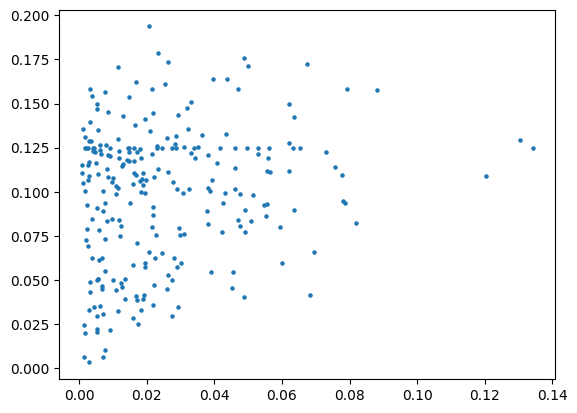

In [23]:
plt.scatter(var_df['Exp_var'], var_df['AUC_var'], s=5)

In [24]:
## Multiply and take top 100 TFs
var_df['Agg_var'] = var_df['Exp_var'] * var_df['AUC_var']

In [25]:
top_TFs = var_df.sort_values('Agg_var', ascending=False)['TF'][0:100]

/tmp/ipykernel_182279/2813989657.py:1: FutureWarning: The behavior of `series[i:j]` with an integer-dtype index is deprecated. In a future version, this will be treated as *label-based* indexing, consistent with e.g. `series[i]` lookups. To retain the old behavior, use `series.iloc[i:j]`. To get the future behavior, use `series.loc[i:j]`.
  top_TFs = var_df.sort_values('Agg_var', ascending=False)['TF'][0:100]


In [26]:
merged_df

,Regulon,AUC,group,TF,TF_target_count,class,Exp
26,AHR_-_+_(93g),1.0,Stemlike_noncycling_TNFRSF19,AHR,93,repressor,0.841205
34,ARID3A_+_+_(214g),1.0,Stemlike_noncycling_TNFRSF19,ARID3A,214,activator,0.415908
74,ASCL2_+_+_(224g),1.0,Stemlike_noncycling_TNFRSF19,ASCL2,224,activator,1.000000
106,ATF4_-_+_(45g),1.0,Stemlike_noncycling_TNFRSF19,ATF4,45,repressor,0.887770
186,BCL11A_+_+_(178g),1.0,Stemlike_noncycling_TNFRSF19,BCL11A,178,activator,0.868191
...,...,...,...,...,...,...,...
2512,ZBTB2_+_+_(14g),0.0,Cycling,ZBTB2,14,activator,0.737448
2520,ZBTB43_+_+_(10g),0.0,Cycling,ZBTB43,10,activator,0.770180
2640,ZNF214_+_+_(23g),0.0,Cycling,ZNF214,23,activator,0.573477
2656,ZNF235_-_+_(19g),0.0,Cycling,ZNF235,19,repressor,0.626230


In [27]:
var_df.sort_values('Agg_var', ascending=False)

,TF,AUC_var,Exp_var,Agg_var
18,BHLHE41,0.129285,0.130500,0.016872
135,MEOX2,0.125000,0.134164,0.016770
101,HOXD3,0.157603,0.088020,0.013872
39,EBF1,0.108892,0.120487,0.013120
12,BARX2,0.158468,0.079326,0.012571
...,...,...,...,...
29,CREB3L2,0.006176,0.007041,0.000043
10,BACH1,0.020134,0.001867,0.000038
20,BPTF,0.024400,0.001451,0.000035
165,PHF20,0.003254,0.003006,0.000010


In [28]:
top_TFs.tolist()

['BHLHE41',
 'MEOX2',
 'HOXD3',
 'EBF1',
 'BARX2',
 'HDX',
 'MYBL1',
 'TCF7L1',
 'E2F8',
 'SOX5',
 'HOXB2',
 'IRF7',
 'IKZF2',
 'POU5F1',
 'NR5A2',
 'ERG',
 'ZEB1',
 'ONECUT3',
 'CREB3L1',
 'FOXM1',
 'MSX2',
 'GATA4',
 'BNC2',
 'E2F2',
 'RARB',
 'HES6',
 'EGR2',
 'ETV1',
 'PROX1',
 'POU2F2',
 'POU5F1B',
 'HHEX',
 'RUNX2',
 'MNX1',
 'ZNF214',
 'KLF2',
 'HOXA11',
 'CEBPA',
 'KLF12',
 'PBX3',
 'MYBL2',
 'ISX',
 'MEIS1',
 'KLF4',
 'SOX2',
 'ARID3A',
 'BHLHE40',
 'SP5',
 'PITX2',
 'HMGA2',
 'HOXA13',
 'NFIC',
 'E2F1',
 'FOXO1',
 'BATF',
 'SOX6',
 'EGR3',
 'FOXN3',
 'SALL4',
 'SREBF1',
 'ZNF566',
 'STAT6',
 'FOXJ1',
 'FOSL1',
 'BCL11A',
 'THRB',
 'FOXD1',
 'FOXP2',
 'NR3C1',
 'ZNF141',
 'SIX4',
 'ZNF93',
 'TCF7',
 'HOMEZ',
 'KLF13',
 'HOXB6',
 'ETS1',
 'PLAG1',
 'TRPS1',
 'ZNF83',
 'NFIB',
 'ZNF235',
 'MEIS2',
 'ZNF100',
 'BCL6',
 'KLF16',
 'E2F5',
 'ZBTB2',
 'LEF1',
 'AHDC1',
 'PHF21A',
 'ZBTB7B',
 'NFKB2',
 'SP4',
 'MAFF',
 'MYB',
 'NR2F2',
 'DRAP1',
 'MECOM',
 'HOXA10']

In [29]:
merged_df['group'].unique()

array(['Stemlike_noncycling_TNFRSF19', 'Stemlike_noncycling',
       'Neuroendocrine', 'MECOMhigh_noncycling', 'KRThigh_noncycling',
       'Differentiated_noncycling', 'Cycling_GATA6', 'Cycling'],
      dtype=object)

In [46]:
## Focusing on activators with at least 50 targets
merged_df_filt = merged_df[(merged_df['class']=='activator') & (merged_df['TF_target_count'] >=50) & (merged_df['TF'].isin(top_TFs))]
auc_pseudo_filt = auc_pseudo.loc[:,merged_df_filt['Regulon'].unique()]

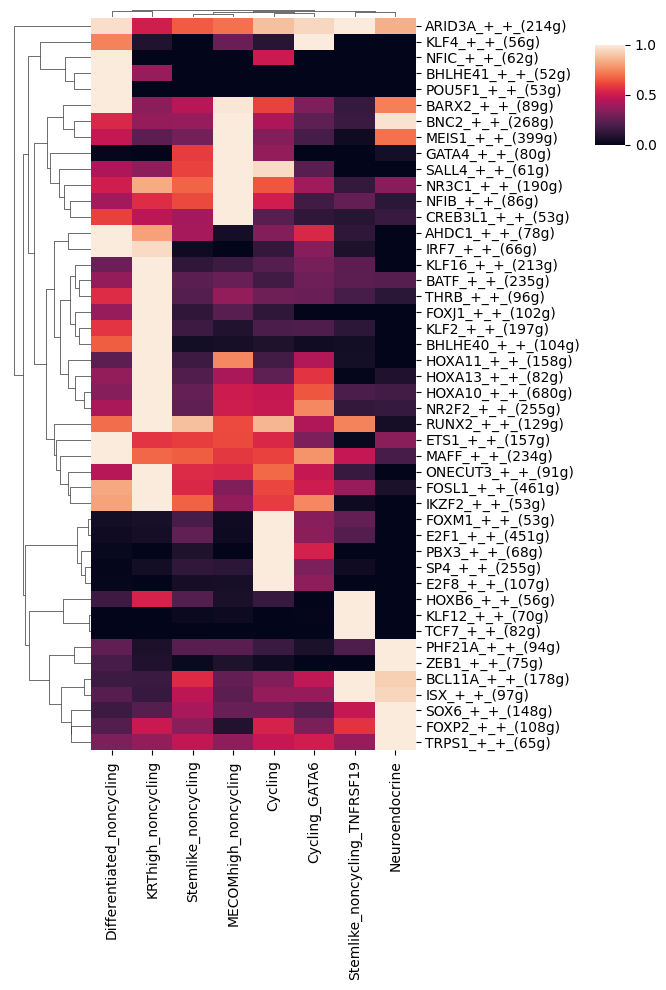

In [47]:
## Cluster based on AUC
g = sns.clustermap(
    auc_pseudo_filt.transpose(),
    xticklabels=True,
    yticklabels=True,
    figsize=(6,10),
    dendrogram_ratio=(0.2, 0.01), 
    cbar_pos=(1, 0.85, 0.05,0.1), 
    method='average')

In [48]:
## Extract clustering:
tf_dendrogram = g.dendrogram_row.linkage
tf_cluster_ids = fcluster(tf_dendrogram , 20, criterion='maxclust')
# Map cluster IDs back to column names
tf_cluster_map = pd.DataFrame({'Regulon':auc_pseudo_filt.columns, 'TF_cluster': tf_cluster_ids})

group_dendrogram_indices = g.dendrogram_col.reordered_ind

In [49]:
group_ordering = auc_pseudo_filt.index[group_dendrogram_indices]

In [50]:
merged_df_filt = pd.merge(merged_df_filt, tf_cluster_map, on ='Regulon', how='left')

In [51]:
merged_df_filt['group'] = pd.Categorical(merged_df_filt['group'], categories=group_ordering, ordered=True)

In [52]:
merged_df_filt = merged_df_filt.sort_values(['TF_cluster', 'TF','group'])

In [53]:
merged_df_filt.head(20)

,Regulon,AUC,group,TF,TF_target_count,class,Exp,TF_cluster
232,BHLHE41_+_+_(52g),1.000000,Differentiated_noncycling,BHLHE41,52,activator,1.000000,1
208,BHLHE41_+_+_(52g),0.376712,KRThigh_noncycling,BHLHE41,52,activator,0.955646,1
88,BHLHE41_+_+_(52g),0.000000,Stemlike_noncycling,BHLHE41,52,activator,0.541590,1
179,BHLHE41_+_+_(52g),0.000000,MECOMhigh_noncycling,BHLHE41,52,activator,0.808270,1
364,BHLHE41_+_+_(52g),0.000000,Cycling,BHLHE41,52,activator,0.469091,1
317,BHLHE41_+_+_(52g),0.000000,Cycling_GATA6,BHLHE41,52,activator,0.342722,1
36,BHLHE41_+_+_(52g),0.000000,Stemlike_noncycling_TNFRSF19,BHLHE41,52,activator,0.134503,1
118,BHLHE41_+_+_(52g),0.000000,Neuroendocrine,BHLHE41,52,activator,0.041120,1
236,NFIC_+_+_(62g),1.000000,Differentiated_noncycling,NFIC,62,activator,0.745426,1
226,NFIC_+_+_(62g),0.000000,KRThigh_noncycling,NFIC,62,activator,0.793973,1


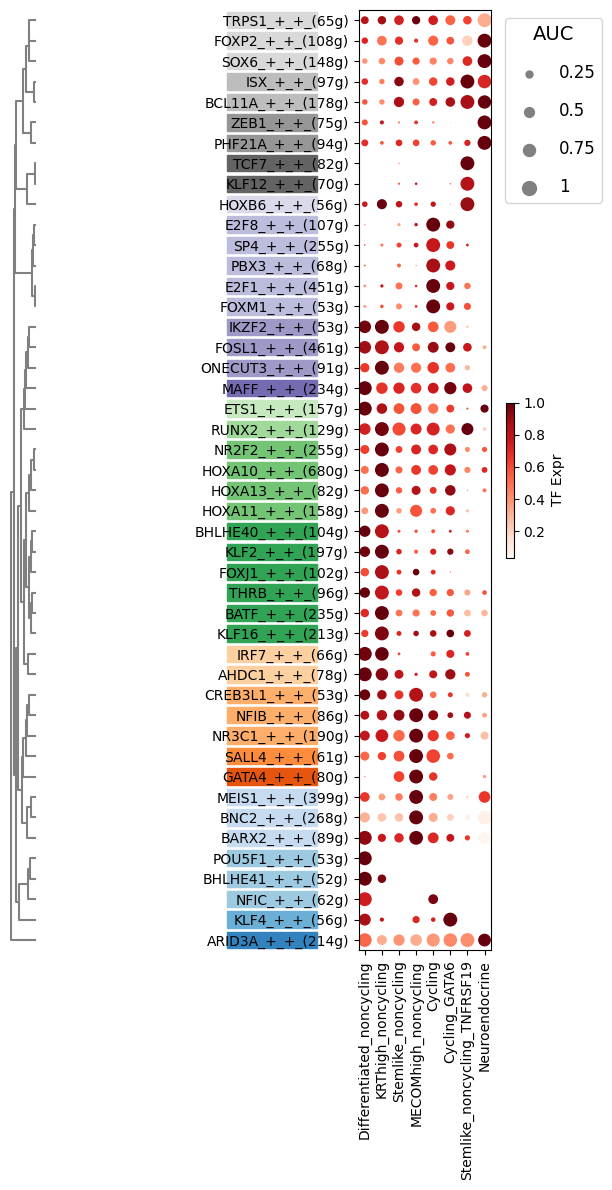

In [92]:
# Create a figure to hold both the dendrogram and the scatter plot
fig, (ax_dendro, ax_scatter) = plt.subplots(1, 2, figsize=(6, 12), gridspec_kw={'width_ratios': [1, 6]})

# Create dendrogram
dendro = dendrogram(tf_dendrogram, orientation='left', ax=ax_dendro, above_threshold_color='gray', color_threshold=0)
ax_dendro.set_xticks([])
ax_dendro.set_yticks([])

for spine in ax_dendro.spines.values():
    spine.set_visible(False)
ax_dendro.set_axis_off()

# Reorder data according to the dendrogram
dendro_order = dendro['leaves']

# Make sure scatterplot order will be the same
merged_df_filt['Regulon'] = pd.Categorical(merged_df_filt['Regulon'], categories=auc_pseudo_filt.columns[dendro_order], ordered=True)
merged_df_filt = merged_df_filt.reset_index(drop=True)
merged_df_filt['dendro_order'] = merged_df_filt['Regulon'].cat.codes
merged_df_filt.sort_values('dendro_order', inplace=True)

size_factor = 100
# Scatterplot
sns.scatterplot(
    data=merged_df_filt,
    x='group',
    y='Regulon',
    size='AUC',
    hue='Exp',
    palette='Reds',
    ax=ax_scatter,
    sizes=(merged_df_filt['AUC'].min()*size_factor, merged_df_filt['AUC'].max()*size_factor),
    legend=False  # We'll add a custom legend later
)
ax_scatter.set_ylim(-0.5, (len(merged_df_filt['Regulon'].unique()) - 0.5))

# Unique clusters for color coding
clusters = merged_df_filt['TF_cluster'].unique()
colors = plt.get_cmap('tab20c').colors
cluster_color = dict(zip(clusters, colors))

# Adding rectangles
for i, regulon in enumerate(merged_df_filt['Regulon'].unique()):
    cluster = merged_df_filt[merged_df_filt['Regulon'] == regulon]['TF_cluster'].iloc[0]
    color = cluster_color[cluster]
    rect = Rectangle((-1, i-0.4), 0.68, 0.8, color=color, transform=ax_scatter.get_yaxis_transform(), clip_on=False)
    ax_scatter.add_patch(rect)

# Create a legend for the sizes
size_values = [0.25, 0.5, 0.75, 1]
size_handles = [plt.scatter([], [], s=size*size_factor, color='gray', label=str(size)) for size in size_values]

## And one for the color
norm = Normalize(vmin=merged_df_filt['Exp'].min(), vmax=merged_df_filt['Exp'].max())
sm = ScalarMappable(cmap="Reds", norm=norm)
sm.set_array([])
colorbar = plt.colorbar(sm, ax=ax_scatter, fraction=0.05, pad=0.1, shrink=0.5)
colorbar.set_label('TF Expr')

legend = ax_scatter.legend(handles=size_handles, title="AUC", labelspacing=1.2,
                           loc='upper left', bbox_to_anchor=(1.05, 1),title_fontsize = 14, fontsize=12)

plt.xlabel('')
plt.ylabel('')
plt.xticks(rotation=90)

plt.tight_layout()

plt.savefig(output_dir + 'GRN_activators_regulons.pdf')
plt.savefig('/nfs/casm/team215mg/users/od5/projects/funcioatlas/multiome/005_GRNs/all_cells/plots/GRN_activators_regulons_highVar.pdf')

plt.show()


In [55]:
merged_df_filt

,Regulon,AUC,group,TF,TF_target_count,class,Exp,TF_cluster,dendro_order
367,ARID3A_+_+_(214g),0.845252,Neuroendocrine,ARID3A,214,activator,1.000000,20,0
365,ARID3A_+_+_(214g),0.947368,Cycling_GATA6,ARID3A,214,activator,0.422743,20,0
364,ARID3A_+_+_(214g),0.885445,Cycling,ARID3A,214,activator,0.385642,20,0
363,ARID3A_+_+_(214g),0.699542,MECOMhigh_noncycling,ARID3A,214,activator,0.321425,20,0
362,ARID3A_+_+_(214g),0.658395,Stemlike_noncycling,ARID3A,214,activator,0.391242,20,0
...,...,...,...,...,...,...,...,...,...
357,TRPS1_+_+_(65g),0.509822,Cycling_GATA6,TRPS1,65,activator,0.534236,19,45
358,TRPS1_+_+_(65g),0.379229,Stemlike_noncycling_TNFRSF19,TRPS1,65,activator,0.620687,19,45
359,TRPS1_+_+_(65g),1.000000,Neuroendocrine,TRPS1,65,activator,0.321681,19,45
352,TRPS1_+_+_(65g),0.319050,Differentiated_noncycling,TRPS1,65,activator,0.820110,19,45


In [56]:
merged_df_filt['TF_cluster'].unique()

array([20,  2,  1,  3,  6,  5,  4,  7,  8,  9, 13, 12, 11, 10, 14, 16, 15,
       17, 18, 19], dtype=int32)

In [53]:
## Save everything we need to reproduce this figure into a dictionary and pickling:
save_dir = {
    'merged_df_filt': merged_df_filt,
    'tf_dendrogram': tf_dendrogram
}

In [54]:
with open((output_dir + 'GRN_activators_AUC_dat.pkl'), 'wb') as f:
    pickle.dump(save_dir, f)

In [55]:
with open((output_dir + 'GRN_activators_AUC_dat.pkl'), 'rb') as f:
    save_dir = pickle.load(f)

In [56]:
save_dir['merged_df_filt'].to_csv(output_dir + 'GRN_activators_AUC.csv')